# 02 — Data Cleaning, Exploratory Data Analysis, dan Text Preprocessing

**Proyek:** Analisis Dinamika Topik Pemberitaan Generative AI pada Media Online Indonesia Menggunakan BERTopic

**Video penjelasan:** `<<TEMPEL LINK VIDEO DI SINI>>`

Notebook ini menjawab Task 2. Prinsipnya: **setiap langkah preprocessing harus punya alasan** yang
berasal dari karakteristik data berita ini dan dari kebutuhan model di hilir — bukan menerapkan semua
teknik secara otomatis. Karena itu dibuat **dua jalur** teks:

| Jalur | Dipakai oleh | Perlakuan |
|---|---|---|
| **A. Teks alami** (`body_clean`, `embed_text`) | IndoBERT, sentence embedding BERTopic, peringkasan | hanya pembersihan ringan; huruf besar, tanda baca, stopword **dipertahankan** |
| **B. Token kosakata** (`tokens`) | BiLSTM, c-TF-IDF BERTopic, LDA, word cloud | case folding, buang angka/tanda baca, tokenisasi, buang stopword, deteksi frasa |

In [1]:
import re, sys, warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from gensim.models.phrases import Phraser, Phrases
from sklearn.feature_extraction.text import TfidfVectorizer
from wordcloud import WordCloud

warnings.filterwarnings("ignore")
ROOT = Path.cwd()   # jalankan notebook dari folder repo
SCRAPED, RES, MODELS, FIG = ROOT / "scraped", ROOT / "results", ROOT / "models", ROOT / "figures"
for _d in (SCRAPED, RES, MODELS, FIG):
    _d.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style="whitegrid")

raw = pd.read_csv(ROOT / "raw_dataset.csv", parse_dates=["date"])
raw[["desc", "tags"]] = raw[["desc", "tags"]].fillna("")
funnel = [("Record mentah hasil scraping", len(raw))]
print(len(raw), "record mentah")

23024 record mentah


## 1. Kode preprocessing

Sel pertama berisi aturan relevansi AI (sama dengan notebook 01); sel kedua berisi fungsi pembersihan
ringan (jalur A) dan tokenisasi + stopword (jalur B).

In [2]:
"""Kriteria relevansi artikel terhadap topik AI / Generative AI.

Artikel dianggap relevan bila AI adalah POKOK berita, bukan sekadar disebut sepintas:
  - judul menyebut istilah AI, ATAU
  - paragraf pembuka (3 paragraf pertama) menyebut istilah AI DAN seluruh isi menyebut istilah AI >= 3 kali.
Berita memakai struktur piramida terbalik: bila AI tidak muncul di judul maupun pembuka, AI hampir pasti
bukan pokok beritanya.

Kata "AI" sendirian ambigu di berita Indonesia:
  - inisial orang: "tersangka AI (25)", "berinisial AI", "Bripka AI", "yakni AI dan A";
  - singkatan lain: "avian influenza (AI)" (flu burung), Amnesty International;
  - "copilot" juga berarti kopilot pesawat ("pilot dan copilot"), yang tidak dihitung.
Pada teks yang memakai "AI" dengan arti lain, kata "AI" tidak dihitung sama sekali.
"""
import re

AI_TERMS = (
    r"kecerdasan buatan|kecerdasan artifisial|artificial intelligence|akal imitasi|"
    r"generative ai|ai generatif|genai|chatgpt|chat gpt|gpt-?\d[\w.]*|openai|gemini ai|google gemini|"
    r"(?<!pilot-)(?<!pilot dan )(?<!pilot )copilot|"
    r"deepseek|deepfake|chatbot|midjourney|large language model|llm|machine learning|"
    r"meta ai|grok ai|claude ai|anthropic"
)
TERM_PATTERN = re.compile(rf"\b(?:{AI_TERMS})\b", re.IGNORECASE)
AI_WORD = re.compile(r"\bA\.?I\b")                       # "AI" huruf kapital

# Penanda orang/pangkat sebelum inisial. "korban"/"pelaku" sengaja tidak dipakai karena berita AI
# sering menulis "korban AI" (korban penyalahgunaan AI) atau "pelaku AI" (pelaku industri AI).
PERSON_CUE = (
    r"inisial|berinisial|berinisal|inisal|tersangka|terdakwa|terpidana|saksi|bocah|sopir|"
    r"sdr\.?|sdri\.?|tn\.?|ny\.?|"
    r"bripka|briptu|bripda|brigadir|aipda|aiptu|ipda|iptu|akp|kompol|serda|sertu|serka|kopda|koptu|pratu|prada"
)
INITIAL_PATTERN = re.compile(
    rf"(?i:\b(?:{PERSON_CUE}))\s+(?:[A-Z]{{1,4}}\s*(?:,|dan|&)\s*)*A\.?I\b"     # "berinisial (RS dan) AI"
    r"|\bA\.?I\s*\(\s*\d{1,2}\s*(?:tahun|th)?\s*\)"                          # "AI (25)"
    r"|\b(?:yakni|yaitu)\s+A\.?I\s+dan\s+[A-Z]{1,3}\b"                        # "yakni AI dan A"
    r"|\badalah\s+A\.?I\s*,\s*(?:seorang|warga|pria|wanita|pemilik|sopir)"   # "adalah AI, seorang ..."
    # relasi keluarga + inisial: "keponakannya, AI", "anaknya AI"
    r"|(?i:\b(?:keponakan|anak|adik|kakak|istri|suami|ayah|cucu|menantu|mertua)(?:nya)?)\s*,?\s+A\.?I\b"
    # dua inisial orang: "AI dan AJ" (bukan akronim teknologi seperti "AI dan ML")
    r"|\bA\.?I\s+dan\s+(?!(?:ML|AR|VR|XR|BI|IT|TI|PC|UI|UX|HP|EV|DL|AI)\b)[A-Z]{1,2}\b"
)
OTHER_SENSE = re.compile(r"avian influenza|flu burung|amnesty international", re.IGNORECASE)

# pola gabungan (dipakai untuk penandaan cepat pada judul/teras)
AI_PATTERN = re.compile(TERM_PATTERN.pattern + r"|\bA\.?I\b")


def ai_mentions(text, gap=25):
    """Jumlah penyebutan AI tanpa hitung ganda.

    - Istilah AI dan kata "AI" yang berjarak < `gap` karakter digabung menjadi satu penyebutan,
      sehingga "kecerdasan buatan atau artificial intelligence (AI)" = 1 penyebutan.
    - Bila teks memakai "AI" sebagai inisial orang atau dengan arti lain, kata "AI" di teks itu tidak
      dihitung; hanya istilah tegas (kecerdasan buatan, ChatGPT, deepfake, ...).
    """
    text = text or ""
    pos = [(m.start(), m.end()) for m in TERM_PATTERN.finditer(text)]
    if not INITIAL_PATTERN.search(text) and not OTHER_SENSE.search(text):
        pos += [(m.start(), m.end()) for m in AI_WORD.finditer(text)]
    pos.sort()
    n, last_end = 0, -10 ** 9
    for a, b in pos:
        if a - last_end >= gap:
            n += 1
        last_end = max(last_end, b)
    return n


def lead_text(body, n_par=3):
    return "\n".join([p for p in (body or "").split("\n") if p.strip()][:n_par])


def is_relevant(title, body):
    """AI di judul, ATAU AI di paragraf pembuka DAN >= 3 penyebutan AI di seluruh isi.
    Judul dinilai bersama isinya agar aturan inisial/arti lain di isi juga berlaku untuk judul."""
    full = f"{title}\n{body}"
    if ai_mentions(title) >= 1 and ai_mentions(full) >= 1:
        return True
    return ai_mentions(lead_text(body)) >= 1 and ai_mentions(full) >= 3

In [3]:
"""Pembersihan dan preprocessing teks berita (dipakai notebook 02 dst)."""
import html
import re

from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory


# ------------------------------------------------------- pembersihan ringan
BOILERPLATE_LINE = re.compile(
    r"^(scroll to (continue|resume) with content|advertisement|iklan|"
    r"(baca|simak|lihat|tonton|saksikan) (juga|pula|video|selengkapnya|halaman|artikel|berita|live)\b.*|"
    r"\[gambas:.*\]|halaman selanjutnya.*|selengkapnya.*di sini.*|"
    r"(lihat|simak) (juga )?(video|foto).*|artikel ini telah tayang.*|"
    r"(pilihan redaksi|berita terkait|rekomendasi untuk anda).*)$",
    re.IGNORECASE,
)
INLINE_JUNK = [
    (re.compile(r"\[Gambas:[^\]]*\]", re.I), " "),
    (re.compile(r"https?://\S+|www\.\S+"), " "),
    (re.compile(r"\S+@\S+\.\S+"), " "),
    # dateline: "Jakarta, CNN Indonesia --" / "Jakarta -"
    (re.compile(r"^\s*[A-Z][\w .]{2,30},\s*CNN Indonesia\s*-+\s*"), ""),
    # dateline Liputan6: "Liputan6.com, Jakarta - " (artikel lama tanpa tanda strip: "Liputan6.com, Jakarta ")
    (re.compile(r"^\s*Liputan6\.com,\s*[A-Z][\w .]{1,30}?\s*-+\s*"), ""),
    (re.compile(r"^\s*Liputan6\.com,\s*[A-Z][a-z]{2,20}\s+"), ""),
    (re.compile(r"^\s*[A-Z][A-Za-z .]{2,25}\s+-\s+(?=[A-Z])"), ""),
    # inisial redaksi di akhir artikel: (asj/fay), (tim/dmi)
    (re.compile(r"\(\s*[a-z]{2,4}\s*/\s*[a-z]{2,4}\s*\)\s*$"), ""),
    # nama media/kanal -> dibuang agar label kelas tidak bocor ke teks
    (re.compile(r"\bdetik\s?(com|inet|finance|edu|health|news|hot|oto|travel|food|sport|x|ers|[a-z]+)?\b", re.I), " "),
    (re.compile(r"\bCNN\s?Indonesia(\.com)?\b|\bCNBC Indonesia\b", re.I), " "),
    (re.compile(r"\bLiputan6(\.com|\.SCTV)?\b|\bShowbiz Liputan6\b", re.I), " "),
]


def clean_text(text):
    """Pembersihan ringan: teks tetap berupa kalimat alami (untuk BERT, embedding, ringkasan)."""
    text = html.unescape(text or "").replace("\xa0", " ")
    lines = []
    for line in text.split("\n"):
        line = line.strip()
        if not line or BOILERPLATE_LINE.match(line):
            continue
        lines.append(line)
    text = "\n".join(lines)
    for pat, rep in INLINE_JUNK:
        text = pat.sub(rep, text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\s+([.,;:!?])", r"\1", text)
    return re.sub(r"\n\s*", "\n", text).strip()


# ------------------------------------------------- preprocessing kosakata
NEWS_STOPWORDS = {
    # kata kerja kutipan & kata umum berita
    "kata", "ujar", "ujarnya", "katanya", "tutur", "tuturnya", "jelas", "jelasnya", "ungkap",
    "ungkapnya", "imbuh", "imbuhnya", "tambah", "tambahnya", "sebut", "menurut", "mengatakan",
    "menyebut", "menjelaskan", "dikutip", "dilansir", "melansir", "mengutip", "dilaporkan",
    "wib", "senin", "selasa", "rabu", "kamis", "jumat", "sabtu", "minggu", "januari", "februari",
    "maret", "april", "mei", "juni", "juli", "agustus", "september", "oktober", "november",
    "desember", "jakarta", "indonesia", "tersebut", "merupakan", "tahun", "hari", "bulan",
    "the", "of", "and", "to", "in", "for", "is", "on", "with", "that", "as", "by", "at", "an",
    "nya", "pun", "kok", "sih", "nih", "yuk", "lho", "kan", "tak", "gak", "nggak", "banget",
    "baca", "simak", "foto", "video", "com", "cnn", "liputan6", "reuters", "afp", "antara", "the", "via",
    "hal", "lalu", "kali", "hingga", "terkait", "salah", "satunya", "sejumlah", "berbagai",
    "sebagai", "bisa", "dapat", "akan", "juga", "lebih", "banyak", "baru", "membuat", "menjadi",
    "melalui", "bahkan", "namun", "sementara", "selain", "saat", "kini", "pihak", "orang",
    "aku", "kamu", "kita", "kami", "mereka", "dia", "anda", "jadi", "satu", "kalau", "kemudian",
    "memiliki", "menggunakan", "beberapa", "sangat", "mulai", "bukan", "dilakukan", "melakukan",
    "memang", "sudah", "belum", "masih", "hanya", "yakni", "yaitu", "seperti", "secara", "tetap",
    "ini", "itu", "para", "sebuah", "dua", "tiga", "persen", "rp", "miliar", "juta", "triliun",
    "ai",  # muncul di hampir semua dokumen -> tidak membedakan topik
}
STOPWORDS = set(StopWordRemoverFactory().get_stop_words()) | NEWS_STOPWORDS
TOKEN_RE = re.compile(r"[a-z][a-z\-]*[a-z]|[a-z]")


def tokenize(text, remove_stopwords=True, min_len=3):
    """Case folding -> buang angka/tanda baca -> tokenisasi -> filter stopword & token pendek."""
    toks = TOKEN_RE.findall((text or "").lower())
    toks = [t.strip("-") for t in toks]
    if remove_stopwords:
        toks = [t for t in toks if len(t) >= min_len and t not in STOPWORDS]
    return toks


def lead(text, n_par=3):
    """Judul + n paragraf pertama dipakai sebagai masukan embedding (piramida terbalik)."""
    return " ".join([p for p in (text or "").split("\n") if p.strip()][:n_par])

## 2. Data cleaning (jalur A)

| Langkah | Alasan |
|---|---|
| Buang record tanpa isi / tanggal di luar periode | scraping gagal atau artikel lama yang ikut muncul di pencarian |
| Deduplikasi URL dan judul | artikel yang sama ditemukan lewat beberapa kata kunci atau diterbitkan ulang di kanal lain; duplikat membuat data test bocor ke train |
| Buang *boilerplate* (`SCROLL TO CONTINUE…`, `ADVERTISEMENT`, `Baca juga: …`, `[Gambas:…]`, URL, inisial redaksi) | bukan isi berita; berulang di ribuan dokumen sehingga mengotori kata kunci topik dan bisa terpilih sebagai kalimat ringkasan |
| Buang *dateline* (`Jakarta, CNN Indonesia --`, `Jakarta -`) | pola pembuka khas tiap media, bukan isi |
| **Buang nama media/kanal** (`detikINET`, `detikcom`, `CNN Indonesia`, …) | label kelas berasal dari kanal → kata ini membocorkan label (*label leakage*) ke model klasifikasi |
| Saring relevansi (fungsi `is_relevant`): AI harus menjadi **pokok berita** — istilah AI ada di **judul**, **atau** ada di **paragraf pembuka** (3 paragraf pertama) **dan** disebut ≥ 3 kali di seluruh isi. Setiap penyebutan dihitung sekali ("berbasis AI" = 1), dan "AI" yang merupakan **inisial orang** ("tersangka AI (25)") tidak dihitung | hasil pencarian memuat banyak artikel yang hanya menyebut AI sepintas (mis. tips jualan online yang menyebut "alat berbasis AI" sekali), ramalan zodiak "Gemini", dan berita kriminal yang memakai inisial "AI". Berita memakai piramida terbalik: bila AI tidak ada di judul maupun pembuka, AI bukan pokok beritanya |
| Simpan artikel 100–3.000 kata | < 100 kata terlalu pendek (pengantar foto/video); > 3.000 kata adalah kompilasi atau teks pidato/dokumen panjang yang bukan berita biasa (±0,5% data) — sekaligus menjaga setiap sel CSV di bawah batas 32.767 karakter Excel |
| Buang *near-duplicate* (cosine TF-IDF > 0,9) | berita yang sama ditulis ulang dengan sedikit perubahan |

In [4]:
df = raw.dropna(subset=["body", "title", "date"]).copy()
df = df[df.body.str.strip().str.len() > 0]
df = df[df.date.between("2022-12-01", "2026-10-31 23:59:59")]
funnel.append(("Punya isi & tanggal dalam periode (Des 2022–Okt 2026)", len(df)))

df = df.drop_duplicates("url")
df["title"] = df["title"].map(lambda t: clean_text(t).replace("\n", " "))
df = df.drop_duplicates(subset=["title"])
funnel.append(("Setelah deduplikasi URL dan judul", len(df)))

df["body_clean"] = df["body"].map(clean_text)
df["desc"] = df["desc"].fillna("").map(lambda t: clean_text(t).replace("\n", " "))
df = df[[is_relevant(t, b) for t, b in zip(df.title, df.body_clean)]]
funnel.append(("Relevan dengan AI (fungsi is_relevant)", len(df)))

df["n_words"] = df["body_clean"].str.split().str.len()
df = df[df.n_words.between(100, 3000)]
funnel.append(("Panjang isi 100–3.000 kata", len(df)))
df = df.sort_values("date").reset_index(drop=True)

In [5]:
# Near-duplicate: cosine similarity TF-IDF > 0.9 -> simpan artikel yang terbit lebih dulu
tf = TfidfVectorizer(max_features=50000, sublinear_tf=True).fit_transform(df["title"] + " " + df["body_clean"])
drop = set()
for start in range(0, tf.shape[0], 1000):
    sims = (tf[start:start + 1000] @ tf.T).tocoo()
    for i, j, v in zip(sims.row + start, sims.col, sims.data):
        if v > 0.9 and j < i and j not in drop:
            drop.add(i)
print("near-duplicate dibuang:", len(drop))
df = df.drop(index=list(drop)).reset_index(drop=True)
funnel.append(("Setelah buang near-duplicate (cosine > 0,9)", len(df)))

near-duplicate dibuang: 248


**Interpretasi funnel cleaning.** Penyusutan terbesar terjadi pada **saringan relevansi**: dari 22.492
artikel unik hanya 10.318 (46%) yang menjadikan AI sebagai pokok berita. Ini sesuai rancangan — empat
domain non-teknologi sengaja diunduh tanpa saringan judul. Aturan relevansi dikembangkan bertahap dengan
membaca contoh data: versi awal masih meloloskan artikel yang hanya menyebut "berbasis AI" sekali, berita
kriminal dengan tersangka berinisial "AI", berita flu burung ("avian influenza (AI)"), dan berita
kecelakaan pesawat ("pilot dan copilot"). Aturan akhir mensyaratkan AI ada di judul, atau di paragraf
pembuka dan disebut ≥ 3 kali, dengan penanganan khusus untuk inisial dan singkatan berarti lain.
Pemeriksaan acak 25 artikel dari dataset akhir menunjukkan seluruhnya membahas AI.

### Penyeimbangan kelas

Domain Teknologi jauh lebih besar dari domain lain. Agar model klasifikasi tidak didominasi satu kelas
dan waktu pelatihan terkendali, kelas terbesar di-*undersample* secara acak (tanpa memilih-milih
periode, sehingga distribusi waktunya tetap) sampai batas `CAP`. Kelas lain dipakai seluruhnya; sisa
ketidakseimbangan ditangani dengan *class weight* pada fungsi loss (notebook 03).

In [6]:
# Batas jumlah dokumen per kelas (kelas terbesar di-undersample)
CAP = 3000
df = (pd.concat([g.sample(min(len(g), CAP), random_state=SEED) for _, g in df.groupby("domain")])
        .sort_values("date").reset_index(drop=True))
df = df.rename(columns={"domain": "label"})
df.insert(0, "doc_id", [f"D{i:05d}" for i in range(len(df))])
funnel.append((f"Dataset akhir (kelas terbesar dibatasi {CAP})", len(df)))
funnel_df = pd.DataFrame(funnel, columns=["tahap", "jumlah_dokumen"])
funnel_df.to_csv(RES / "cleaning_funnel.csv", index=False)
funnel_df

,tahap,jumlah_dokumen
0,Record mentah hasil scraping,23024
1,Punya isi & tanggal dalam periode (Des 2022–Ok...,22513
2,Setelah deduplikasi URL dan judul,22492
3,Relevan dengan AI (fungsi is_relevant),10318
4,Panjang isi 100–3.000 kata,10279
5,"Setelah buang near-duplicate (cosine > 0,9)",10031
6,Dataset akhir (kelas terbesar dibatasi 3000),6714


### Contoh sebelum dan sesudah pembersihan (jalur A)

In [7]:
ex = df[df.body.str.contains("SCROLL TO CONTINUE", case=False)].iloc[3]
print("SEBELUM:\n", ex.body[:900], "\n\n" + "-" * 100 + "\n\nSESUDAH:\n", ex.body_clean[:800])

SEBELUM:
 Belakangan di media sosial tengah viral mengenai ChatGPT , AI berbasis percakapan yang bisa ditanyai berbagai topik, dari mulai membuat rencana liburan sampai pidato kepresidenan.
Di balik ChatGPT ini ada OpenAI, sebuah lembaga nonprofit yang melakukan riset kecerdasan buatan (artificial intelligence/AI). Lembaga ini melakukan riset di bidang AI dengan tujuan mempromosikan dan mengembangkan AI yang bisa berguna untuk manusia.
OpenAI didirikan di San Francisco pada 2015 oleh Elon Musk, Sam Altman, dan beberapa orang lain. Elon Musk tentu sudah tenar dan tak perlu diperkenalkan lagi, sementara Altman adalah seorang entrepreneur, investor, program, dan mantan presiden Y Combinator.
SCROLL TO CONTINUE WITH CONTENT
Para pendirinya ini mengumpulkan uang sebesar USD 1 miliar untuk menjadi modal awal OpenAI. Elon sendiri akhirnya mengundurkan diri pada Februari 2018 namun tetap menjadi penyumban 

---------------------------------------------------------------------------------------

## 3. Exploratory Data Analysis

In [8]:
print("Jumlah dokumen:", len(df), "| periode:", df.date.min().date(), "s.d.", df.date.max().date())
dist = pd.crosstab(df["label"], df["source"], margins=True)
dist["persen"] = (100 * dist["All"] / len(df)).round(1)
dist.to_csv(RES / "eda_label_source.csv")
dist

Jumlah dokumen: 6714 | periode: 2022-12-05 s.d. 2026-10-31


source,cnn,detik,liputan6,All,persen
label,,,,,
Ekonomi,183,493,303,979,14.6
Hiburan,106,396,245,747,11.1
Nasional,87,1119,68,1274,19.0
Pendidikan,6,708,0,714,10.6
Teknologi,511,1934,555,3000,44.7
All,893,4650,1171,6714,100.0


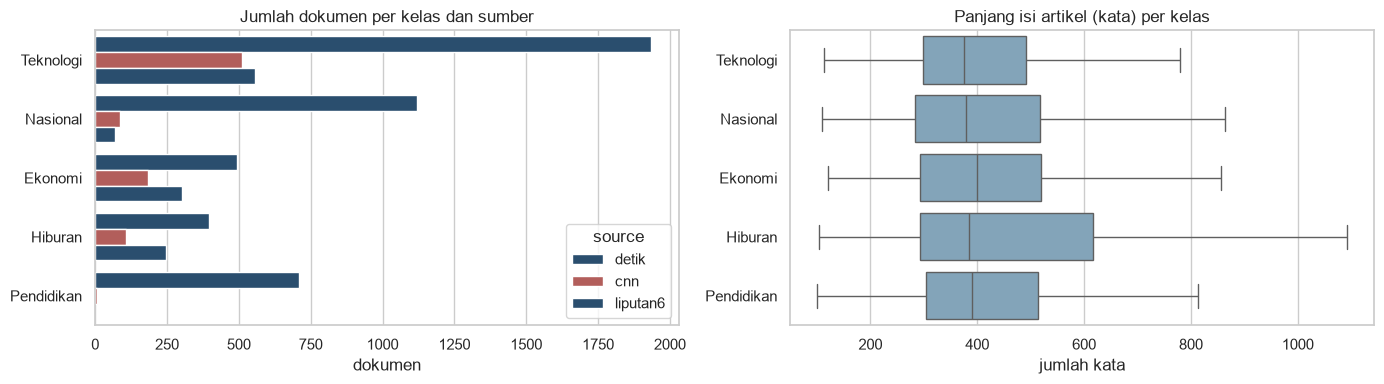

,count,mean,50%,min,max
label,,,,,
Ekonomi,979.0,430.0,399.0,120.0,2254.0
Hiburan,747.0,524.0,385.0,104.0,2687.0
Nasional,1274.0,444.0,378.0,110.0,2682.0
Pendidikan,714.0,428.0,390.0,100.0,1708.0
Teknologi,3000.0,418.0,374.0,113.0,2331.0
SEMUA,6714.0,438.0,382.0,100.0,2687.0


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
order = df.label.value_counts().index
sns.countplot(data=df, y="label", hue="source", order=order, ax=ax[0], palette=["#1f4e79", "#c0504d"])
ax[0].set_title("Jumlah dokumen per kelas dan sumber"); ax[0].set_xlabel("dokumen"); ax[0].set_ylabel("")
sns.boxplot(data=df, y="label", x="n_words", order=order, ax=ax[1], color="#7aa6c2", showfliers=False)
ax[1].set_title("Panjang isi artikel (kata) per kelas"); ax[1].set_xlabel("jumlah kata"); ax[1].set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "02_label_length.png", dpi=150); plt.show()
stats = df.groupby("label")["n_words"].describe()[["count", "mean", "50%", "min", "max"]].round(0)
stats.loc["SEMUA"] = df["n_words"].describe()[["count", "mean", "50%", "min", "max"]].round(0)
stats.to_csv(RES / "eda_length.csv")
stats

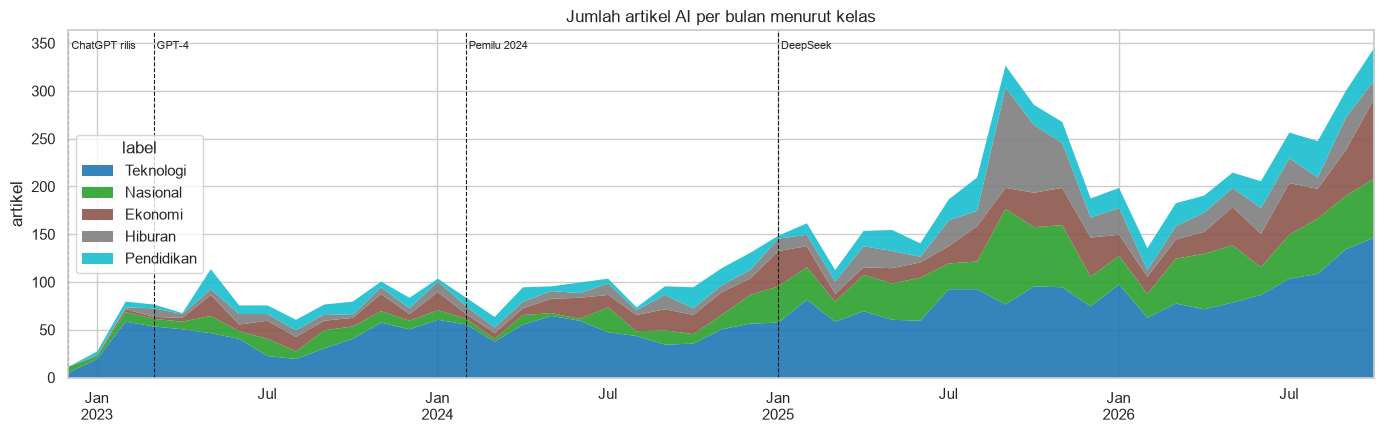

source,cnn,detik,liputan6,All
date,,,,
2022,2,10,0,12
2023,152,645,125,922
2024,141,868,149,1158
2025,224,1624,492,2340
2026,374,1503,405,2282
All,893,4650,1171,6714


In [10]:
# Volume pemberitaan per bulan + penanda peristiwa besar
monthly = df.set_index("date").groupby([pd.Grouper(freq="MS"), "label"]).size().unstack(fill_value=0)
ax = monthly[order].plot.area(figsize=(14, 4.5), cmap="tab10", lw=0, alpha=0.9)
events = {"2022-12-01": "ChatGPT rilis", "2023-03-14": "GPT-4", "2024-02-14": "Pemilu 2024", "2025-01-27": "DeepSeek"}
for d, name in events.items():
    ax.axvline(pd.Timestamp(d), color="k", lw=0.8, ls="--")
    ax.text(pd.Timestamp(d), ax.get_ylim()[1] * 0.97, " " + name, fontsize=8, va="top")
ax.set_title("Jumlah artikel AI per bulan menurut kelas"); ax.set_xlabel(""); ax.set_ylabel("artikel")
plt.tight_layout(); plt.savefig(FIG / "02_monthly_volume.png", dpi=150); plt.show()
yearly = pd.crosstab(df.date.dt.year, df.source, margins=True)
yearly.to_csv(RES / "eda_yearly.csv")
yearly

In [11]:
pd.set_option("display.max_colwidth", 160)
df.groupby("label").sample(1, random_state=3)[["label", "source", "date", "title", "body_clean"]]

,label,source,date,title,body_clean
4236,Ekonomi,detik,2025-11-29 16:55:16,RI Mulai Jajaki Pembangkit Listrik Berbasis AI,Indonesia mulai menjajaki pengembangan pembangkit listrik berbasis teknologi kecerdasan buatan (AI). Upaya ini dilakukan lewat studi bersama antara PLN Indo...
3976,Hiburan,liputan6,2025-11-01 10:33:00,"7 Prompt AI Edit Foto Gaya OOTD yang Lagi Trend, Realistis dan Estetik","Fenomena foto OOTD ( Outfit of the Day ) kini tidak hanya menjadi ekspresi gaya pribadi, tetapi juga bentuk visual storytelling yang menggambarkan identitas..."
1977,Nasional,detik,2024-12-04 23:30:17,"Mengenal Meta AI, Penjelasan dan Cara Pakainya",Perusahaan Meta mengembangkan sebuah teknologi berbasis kecerdasan buatan bernama Meta AI. Teknologi tersebut ditujukan untuk dapat membantu pengguna dalam ...
345,Pendidikan,detik,2023-05-23 16:30:00,Bos Microsoft: Indonesia Perlu AI dalam Pemerataan Akses Pendidikan,"Artificial Intelligence (AI) atau kecerdasan buatan saat ini tengah hangat dibicarakan oleh masyarakat terlebih setelah munculnya chatbot seperti ChatGPT, G..."
2436,Teknologi,detik,2025-03-10 22:00:09,"Ngeri, AI Akan Jadi Mata Pelajaran di SD dan SMP China","Anak-anak usia sekolah di Beijing, ibu kota China, akan diajari AI sejak usia dini. Sekolah dasar dan sekolah menengah di kota tersebut akan memperkenalkan ..."


**Interpretasi EDA.**

- **Distribusi label.** Teknologi 45% data (dibatasi 3.000), Nasional 19%, Ekonomi 15%, Hiburan 11%,
  Pendidikan 11%. Rasio kelas terbesar : terkecil ≈ 4 : 1, sehingga ditangani dengan *class weight* dan
  dievaluasi dengan macro-F1.
- **Sumber.** 69% artikel dari Detik, 17% Liputan6, 13% CNN. Pendidikan hampir seluruhnya dari detikEdu
  (CNN hanya 6 artikel AI di kanal Edukasi, Liputan6 tidak punya kanal pendidikan); ini perlu diingat saat
  menafsirkan perbedaan antar-media.
- **Panjang teks.** Median 382 kata; artikel > 3.000 kata dibuang sebagai kompilasi/teks pidato. Panjang
  masukan IndoBERT 256 token (±190 kata) sudah mencakup sekitar separuh artikel biasa, termasuk bagian
  awal yang memuat inti berita.
- **Tren waktu.** Volume artikel AI naik dua kali lipat dari ±900 (2023) dan ±1.150 (2024) menjadi ±2.300
  pada 2025 dan Januari–Oktober 2026, dengan puncak bulanan September–Oktober 2025 dan September–Oktober
  2026. Kenaikan paling tajam terjadi di **Nasional** (±130 artikel per tahun pada 2023–2024 menjadi ±500
  pada 2025) dan **Hiburan** (±70–100 per tahun menjadi ±370 pada 2025): AI tidak lagi hanya berita teknologi, tetapi
  merembes ke berita kriminal, pemerintahan, dan gaya hidup.

## 4. Text preprocessing jalur B (token kosakata)

| Langkah | Diterapkan? | Alasan |
|---|---|---|
| Case folding | ya | "AI", "Ai", "ai" harus dihitung sebagai kata yang sama |
| Buang angka & tanda baca | ya | angka (tanggal, harga, versi) tidak membawa tema; tanda baca bukan kosakata |
| Tokenisasi (regex kata beralfabet) | ya | satuan dasar untuk kosakata BiLSTM, c-TF-IDF, dan LDA |
| Buang stopword (Sastrawi + daftar khusus berita) | ya | kata fungsi dan kata kutipan berita ("kata", "ujar", "menurut", nama hari/bulan, "jakarta") muncul di semua dokumen sehingga mendominasi kata kunci topik tanpa makna tematik |
| Buang token < 3 huruf | ya | hampir semuanya partikel/singkatan tak bermakna ("di", "ke", "yg") |
| Deteksi frasa (bigram statistik) | ya | "kecerdasan buatan", "media sosial", "sam altman" adalah satu konsep; digabung jadi `kecerdasan_buatan` agar kata kunci topik lebih bermakna |
| **Stemming / lemmatization** | **tidak** | (1) kata kunci topik harus tetap terbaca manusia — stemmer Sastrawi mengubah "pengguna"→"guna", "pendidikan"→"didik"; (2) imbuhan membawa makna berbeda ("pekerja" vs "pekerjaan"); (3) merusak istilah asing/nama produk yang dominan di korpus ini (mis. "meta", "gemini"); (4) IndoBERT memakai WordPiece yang sudah menangani variasi morfologi |
| Normalisasi kata gaul | tidak | teks berita ditulis baku; di data ini nyaris tidak ada kata gaul |

Untuk **IndoBERT, sentence embedding, dan peringkasan**, langkah-langkah di atas **tidak** diterapkan:
model transformer di-*pretrain* pada kalimat utuh, dan ringkasan ekstraktif harus berupa kalimat asli.

In [12]:
tok = [tokenize(t + " " + b) for t, b in zip(df.title, df.body_clean)]
phraser = Phraser(Phrases(tok, min_count=20, threshold=12, delimiter="_"))
tok = [phraser[t] for t in tok]
df["tokens"] = [" ".join(t) for t in tok]
df["n_tokens"] = [len(t) for t in tok]
df["embed_text"] = [t + ". " + lead(b, 3) for t, b in zip(df.title, df.body_clean)]

vocab_raw = Counter(w for b in df.body_clean for w in b.lower().split())
vocab_tok = Counter(w for t in tok for w in t)
prep_stats = pd.DataFrame({
    "sebelum (teks alami, split spasi)": [int(df.n_words.sum()), len(vocab_raw), round(df.n_words.mean(), 1)],
    "sesudah (token jalur B)": [int(df.n_tokens.sum()), len(vocab_tok), round(df.n_tokens.mean(), 1)],
}, index=["total token", "ukuran kosakata", "rata-rata token per dokumen"])
prep_stats.to_csv(RES / "prep_stats.csv")
print("Contoh frasa terdeteksi:", [w for w, _ in vocab_tok.most_common(4000) if "_" in w][:25])
prep_stats

Contoh frasa terdeteksi: ['kecerdasan_buatan', 'artificial_intelligence', 'masa_depan', 'media_sosial', 'latar_belakang', 'amerika_serikat', 'kerja_sama', 'pusat_data', 'data_center', 'sumber_daya', 'elon_musk', 'perkembangan_teknologi', 'memungkinkan_pengguna', 'bertanggung_jawab', 'sam_altman', 'prompt_gemini', 'tata_kelola', 'sebagian_besar', 'keamanan_siber', 'transformasi_digital', 'kecerdasan_artifisial', 'luar_biasa', 'bekerja_sama', 'google_gemini', 'perangkat_lunak']


,"sebelum (teks alami, split spasi)",sesudah (token jalur B)
total token,2937987.0,1689345.0
ukuran kosakata,123901.0,57939.0
rata-rata token per dokumen,437.6,251.6


In [13]:
ex = df.iloc[len(df) // 2]
print("JUDUL   :", ex.title)
print("\nTEKS ALAMI (jalur A, 60 kata pertama):\n", " ".join(ex.body_clean.split()[:60]))
print("\nTOKEN (jalur B, 40 token pertama):\n", ex.tokens.split()[:40])

JUDUL   : Percepat Adopsi AI di Indonesia, Telkom Solution Luncurkan Telkom AI Center of Excellence

TEKS ALAMI (jalur A, 60 kata pertama):
 Telkom Solution resmi meluncurkan Telkom AI Center of Excellence yang bertepatan dengan penyelenggaraan Bali Annual Telkom International Conference (BATIC) edisi ke-10 di Bali International Convention Center. Inisiatif strategis ini dipimpin oleh Direktur Enterprise & Business Service Telkom, Veranita Yosephine, bersama Direktur IT Digital Telkom, Faizal Rochmad Djoemadi, sebagai langkah mempercepat implementasi kecerdasan buatan (AI) di Indonesia. Peluncuran AI Center ini

TOKEN (jalur B, 40 token pertama):
 ['percepat', 'adopsi', 'telkom', 'solution', 'luncurkan', 'telkom', 'center_excellence', 'telkom', 'solution', 'resmi_meluncurkan', 'telkom', 'center_excellence', 'bertepatan', 'penyelenggaraan', 'bali', 'annual', 'telkom', 'international_conference', 'batic', 'edisi', 'bali', 'international', 'convention_center', 'inisiatif', 'strategis', 'd

## 5. EDA pada token: kata paling sering dan word cloud per kelas

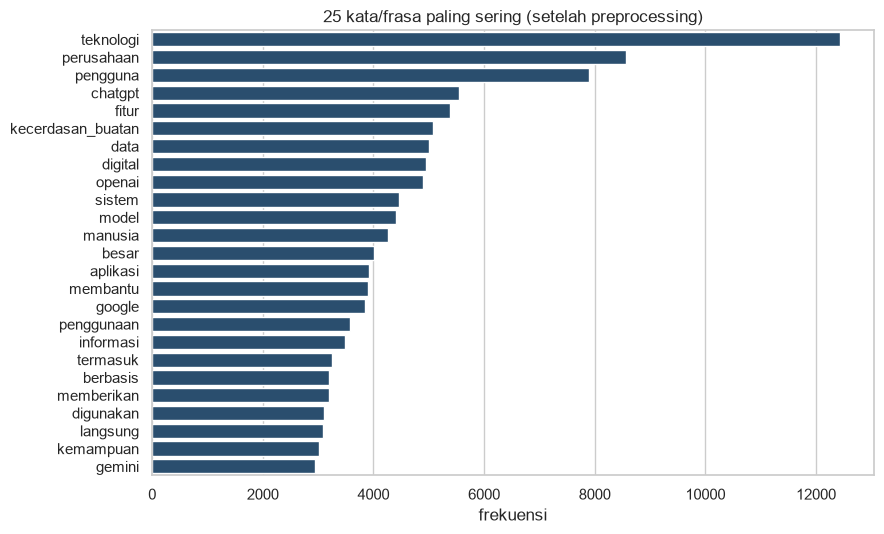

In [14]:
top_all = pd.DataFrame(vocab_tok.most_common(25), columns=["kata", "frekuensi"])
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(data=top_all, y="kata", x="frekuensi", color="#1f4e79", ax=ax)
ax.set_title("25 kata/frasa paling sering (setelah preprocessing)"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "02_top_words.png", dpi=150); plt.show()

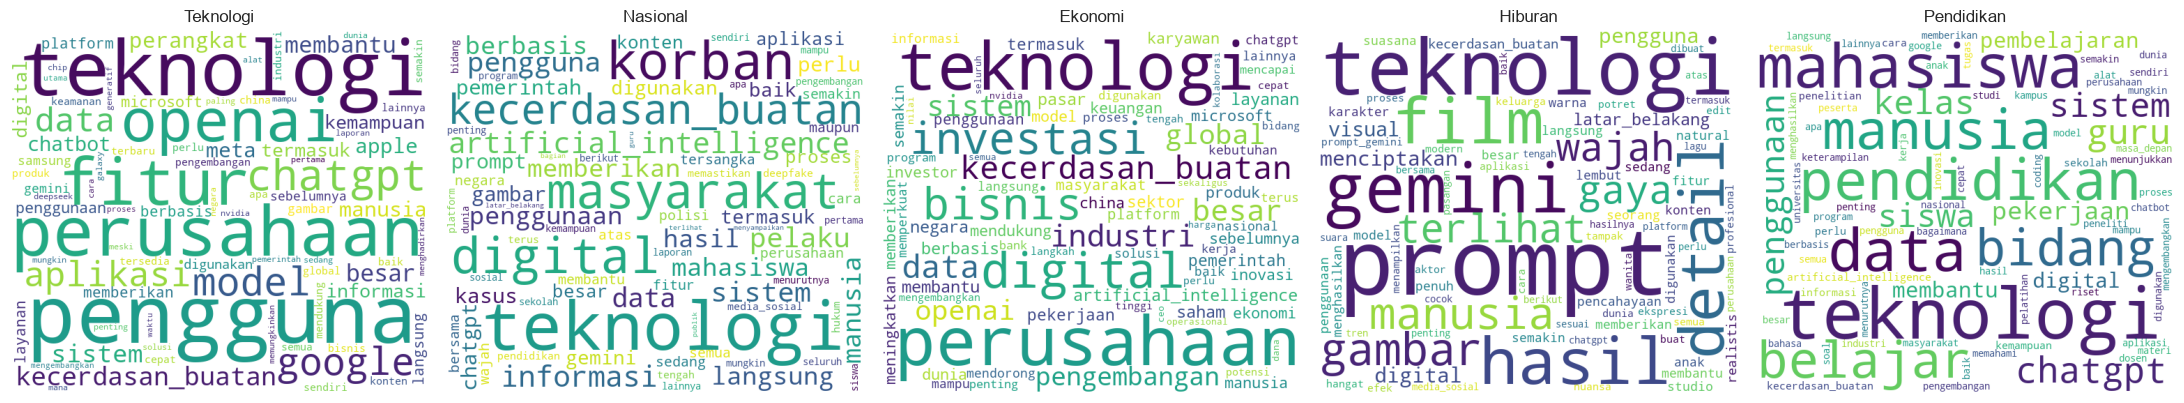

,15 kata paling sering
Teknologi,"pengguna, teknologi, perusahaan, fitur, openai, chatgpt, model, google, aplikasi, data, kecerdasan_buatan, sistem, besar, membantu, perangkat"
Nasional,"teknologi, korban, digital, masyarakat, kecerdasan_buatan, artificial_intelligence, informasi, sistem, pengguna, pelaku, data, manusia, mahasiswa, berbasis,..."
Ekonomi,"perusahaan, teknologi, digital, bisnis, investasi, kecerdasan_buatan, data, industri, besar, sistem, openai, global, pengembangan, artificial_intelligence, ..."
Hiburan,"prompt, teknologi, gemini, hasil, film, detail, gambar, manusia, terlihat, wajah, gaya, menciptakan, digital, pengguna, visual"
Pendidikan,"teknologi, mahasiswa, data, pendidikan, manusia, belajar, bidang, chatgpt, guru, kelas, sistem, penggunaan, siswa, pekerjaan, pembelajaran"


In [15]:
labels = list(order)
fig, axes = plt.subplots(1, len(labels), figsize=(4.4 * len(labels), 4))
top_by_class = {}
for ax, lab in zip(axes, labels):
    c = Counter(w for t in df[df.label == lab]["tokens"] for w in t.split())
    top_by_class[lab] = ", ".join(w for w, _ in c.most_common(15))
    ax.imshow(WordCloud(width=600, height=520, background_color="white", colormap="viridis",
                        max_words=80, random_state=SEED).generate_from_frequencies(c))
    ax.set_title(lab); ax.axis("off")
plt.tight_layout(); plt.savefig(FIG / "02_wordcloud.png", dpi=150); plt.show()
pd.Series(top_by_class, name="15 kata paling sering").to_frame()

In [16]:
# Kata paling KHAS per kelas (TF-IDF rata-rata kelas dikurangi rata-rata keseluruhan):
# berbeda dari kata paling sering, ini menunjukkan apa yang membedakan satu kelas dari kelas lain.
tv = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, min_df=10, max_df=0.7)
X = tv.fit_transform(df["tokens"]); terms = np.array(tv.get_feature_names_out())
overall = np.asarray(X.mean(0)).ravel()
distinct = {lab: ", ".join(terms[np.argsort(-(np.asarray(X[(df.label == lab).values].mean(0)).ravel() - overall))[:12]])
            for lab in labels}
dd = pd.Series(distinct, name="12 kata paling khas").to_frame()
dd.to_csv(RES / "eda_distinct_words.csv")
dd

,12 kata paling khas
Teknologi,"pengguna, openai, fitur, google, chatgpt, apple, meta, samsung, model, perangkat, perusahaan, microsoft"
Nasional,"korban, pelaku, tersangka, polisi, masyarakat, polri, chiko, kasus, jokowi, mahasiswa, warga, artificial_intelligence"
Ekonomi,"perusahaan, investasi, saham, bisnis, keuangan, karyawan, investor, pasar, luhut, bri, bank, industri"
Hiburan,"film, prompt, aktor, lagu, wanita, wajah, musik, detail, gemini, studio, karakter, gaya"
Pendidikan,"mahasiswa, kelas, pendidikan, guru, belajar, siswa, pembelajaran, penelitian, sekolah, bidang, peserta, dosen"


**Interpretasi kata.** Kata paling sering secara keseluruhan (teknologi, perusahaan, digital, pengguna,
data, kecerdasan_buatan) bersifat umum dan muncul di semua kelas — karena itu kata yang **khas** per kelas
lebih informatif: Teknologi didominasi nama perusahaan/produk (openai, chatgpt, google, apple, meta,
samsung), Nasional oleh kosakata kriminal dan aparat (korban, pelaku, tersangka, polisi), Ekonomi oleh
investasi dan pasar (investasi, saham, investor, karyawan), Pendidikan oleh dunia kampus/sekolah
(mahasiswa, guru, siswa, pembelajaran), dan Hiburan oleh film, musik, dan tren edit foto (film, prompt,
aktor, lagu, gemini). Perbedaan kosakata ini menunjukkan kelima domain dapat dipisahkan oleh model,
sementara kata umum yang sama di semua kelas menjelaskan mengapa kesalahan klasifikasi akan terkonsentrasi
pada artikel "AI umum" yang tidak memuat kata khas domain mana pun.

## 6. Simpan dataset bersih

In [17]:
keep = ["doc_id", "source", "url", "label", "channel", "title", "desc", "date", "body_clean", "embed_text",
        "tokens", "n_words", "n_tokens"]
df[keep].to_csv(ROOT / "dataset_clean.csv", index=False, encoding="utf-8-sig")
phraser.save(str(MODELS / "phraser.pkl"))
print("tersimpan: dataset_clean.csv |", len(df), "dokumen,", df.label.nunique(), "kelas")
df.label.value_counts()

tersimpan: dataset_clean.csv | 6714 dokumen, 5 kelas


label
Teknologi     3000
Nasional      1274
Ekonomi        979
Hiburan        747
Pendidikan     714
Name: count, dtype: int64